# Figure 5 — Synaptic filtering

Pena, Vellmer, Bernardi, Roque & Lindner (2018), Front. Comput. Neurosci. 12:9, doi:10.3389/fncom.2018.00009. Scheme after Dummer, Wieland & Lindner (2014).

**Caption (paper):** The scheme also works with synaptic filtering. (A) Spectra of network and scheme for several τs (exponential synapses, J = 0.2 mV, inhibition-dominated, low rates). (B, C) τs = 10 ms: Fano factor and correlation time vs J. Other parameters as in Figure 4.

**Method here:** Eq. 10 filter in the scheme (|K̃|² in Eq. 13) and a charge-preserving exponential synaptic current in the network (N_E = 8,000, dt = 0.05 ms). τs = 0 reuses the Figure 4 runs.

**Shared implementation choices** (all figures, see `pena_scheme.py`, `pena_network.py`):
- Euler, `dt = 0.1 ms`; voltage clamped at reset during the refractory period (scheme and network).
- Spectra: Eq. 5, two-sided, 2 s windows after a 1 s transient (Δf = 0.5 Hz).
  Fano factor = mean of S at 0.5 and 1 Hz divided by ν; τc from Eq. 7 with the estimator variance subtracted.
- Scheme generation 0: white noise at the diffusion-approximation (mean-field) rate; the paper does not
  specify its starting point. Inhibition-dominated cases (g > 4) use the all-past rate average (Eq. 11).
- Networks are simulated at reduced size (default N_E = 10,000 instead of 100,000) to fit 2 CPUs / ~2 GB;
  partners are drawn with replacement. Larger sizes are available via the config cell but need far more memory.

In [1]:
from pathlib import Path
import sys, json, time
import numpy as np
import matplotlib.pyplot as plt

HERE = Path.cwd()
if not (HERE / "pena2018_params.py").exists():
    HERE = HERE / "05_Pena2018_Replication"
sys.path.insert(0, str(HERE))

from pena2018_params import params_for
import pena_scheme as ps
import pena_runs as pr
FIGURES = HERE / "figures"; FIGURES.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

In [2]:
P = params_for(5)
TAU_S = [0.0, 2.0, 5.0, 10.0, 20.0]       # the paper's τs grid is not listed
J_VALUES = [0.1, 0.2, 0.3, 0.4, 0.6, 0.8, 1.0]
TAU_S_BC = 10.0
N_E_NET, N_WINDOWS, NET_DT = 8_000, 10, 0.05
SCHEME = dict(n_generations=40, n_trials=1000)

In [3]:
runsA = {}
for ts in TAU_S:
    p = dict(P, J=0.2, tau_s=ts)
    print(f"--- tau_s = {ts} ms")
    runsA[ts] = (pr.homogeneous_scheme(p, **SCHEME), pr.homogeneous_network(p, N_E_NET, N_WINDOWS, dt=NET_DT))
runsBC = {}
for J in J_VALUES:
    p = dict(P, J=J, tau_s=TAU_S_BC)
    print(f"--- J = {J} mV, tau_s = {TAU_S_BC} ms")
    runsBC[J] = (pr.homogeneous_scheme(p, **SCHEME), pr.homogeneous_network(p, N_E_NET, N_WINDOWS, dt=NET_DT))

--- tau_s = 0.0 ms
loaded scheme_homog_dc0d9f900d.npz
loaded net_homog_bc3348a8eb.npz
--- tau_s = 2.0 ms


gen  0:    9.59->   9.66 Hz


gen  1:    9.66->   8.81 Hz


gen  2:    8.81->  10.14 Hz


gen  3:    9.47->   8.90 Hz


gen  4:    9.28->   9.30 Hz


... (401 outputs left out)

gen 37:   46.09->  46.30 Hz


gen 38:   46.09->  46.14 Hz


gen 39:   46.09->  44.91 Hz


gen 40:   46.06->  43.96 Hz
saved scheme_homog_e35442c626.npz (87 s)
loaded net_homog_1262c0d5e3.npz


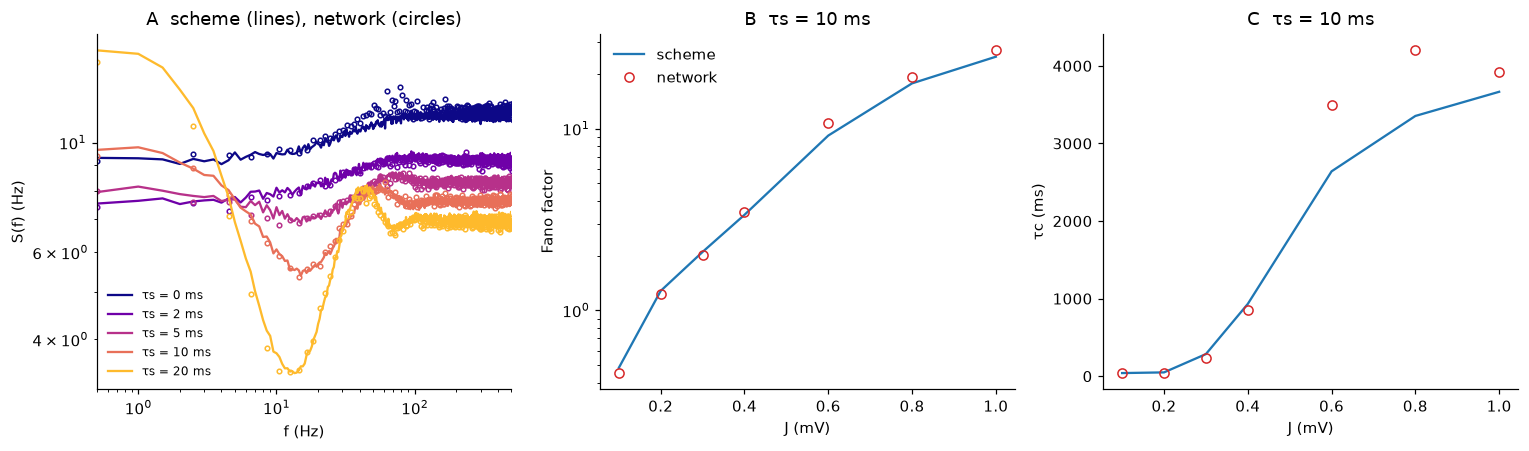

saved figure05_synaptic_filter.csv (12533 data points)


PosixPath('/workspaces/SC_Cortex/05_Pena2018_Replication/figures/figure05_synaptic_filter.csv')

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
cols = plt.cm.plasma(np.linspace(0, 0.85, len(TAU_S)))
for c, ts in zip(cols, TAU_S):
    s, n = runsA[ts]
    axes[0].loglog(s["f"], s["S_final"][0], color=c, label=f"τs = {ts:g} ms")
    axes[0].loglog(n["f"][1::4], n["S_E"][1::4], "o", ms=3, mfc="none", color=c)
axes[0].set(xlim=(0.5, 500), xlabel="f (Hz)", ylabel="S(f) (Hz)", title="A  scheme (lines), network (circles)")
axes[0].legend(frameon=False, fontsize=8)
for ax, ks, kn, yl, sc, t in [(axes[1], "FF", "FF_E", "Fano factor", 1, "B"),
                              (axes[2], "tau_c", "tau_c_E", "τc (ms)", 1e3, "C")]:
    ax.plot(J_VALUES, [float(runsBC[J][0][ks][0]) * sc for J in J_VALUES], "-", label="scheme")
    ax.plot(J_VALUES, [float(runsBC[J][1][kn]) * sc for J in J_VALUES], "o", mfc="none", color="tab:red", label="network")
    ax.set(xlabel="J (mV)", ylabel=yl, title=f"{t}  τs = {TAU_S_BC:g} ms")
axes[1].set_yscale("log"); axes[1].legend(frameon=False)
fig.tight_layout(); fig.savefig(FIGURES / "figure05_synaptic_filter.png", dpi=200); plt.show()
import pena_export; pena_export.figure_csv(fig, FIGURES / "figure05_synaptic_filter.csv")

In [5]:
for ts in TAU_S:
    s, n = runsA[ts]
    print(f"tau_s={ts:4.1f}: nu scheme {float(s['nu_final'][0]):6.2f}  net {float(n['nu_E']):6.2f} Hz")
for J in J_VALUES:
    s, n = runsBC[J]
    print(f"J={J:3.1f}: FF {float(s['FF'][0]):6.2f}/{float(n['FF_E']):6.2f}  tau_c {1e3*float(s['tau_c'][0]):6.1f}/{1e3*float(n['tau_c_E']):6.1f} ms")

tau_s= 0.0: nu scheme  11.27  net  11.67 Hz
tau_s= 2.0: nu scheme   9.26  net   9.19 Hz
tau_s= 5.0: nu scheme   8.34  net   8.31 Hz
tau_s=10.0: nu scheme   7.60  net   7.65 Hz
tau_s=20.0: nu scheme   7.03  net   6.91 Hz
J=0.1: FF   0.48/  0.45  tau_c   40.7/  41.8 ms
J=0.2: FF   1.28/  1.23  tau_c   49.4/  40.3 ms
J=0.3: FF   2.10/  2.02  tau_c  285.4/ 237.4 ms
J=0.4: FF   3.36/  3.47  tau_c  931.9/ 859.8 ms
J=0.6: FF   9.17/ 10.77  tau_c 2640.6/3491.5 ms
J=0.8: FF  17.76/ 19.22  tau_c 3354.4/4200.6 ms
J=1.0: FF  24.90/ 27.01  tau_c 3665.9/3919.1 ms


## Notes

_Filled in after the run._